# Qiskit Fall Fest 2026 — Challenge 1: Predict the Output
**IBM Quantum | Vishnu Institute of Technology**

## Aim
Build three one-qubit circuits (X, X–X and H), **predict** what each will measure, run each one for **100 shots**, plot the results as histograms, and then check the predictions against what actually happened.

## 1. Setup
Run the install cell once if Qiskit is missing (works on Google Colab too). The main experiment runs on the local Aer simulator; Section 9 optionally repeats it on a real IBM Quantum device.

In [ ]:
%pip install -q qiskit qiskit-aer matplotlib pylatexenc

In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

SHOTS = 100                 # every experiment uses 100 shots
sim = AerSimulator()        # local simulator
print(f"Ready: {SHOTS} shots per circuit on {sim.name}")

Ready: 100 shots per circuit on aer_simulator


## 2. Predictions (written before running anything)

All circuits start with the qubit in |0⟩.

| Circuit | Gates | Predicted result | Why |
|---|---|---|---|
| A | X | all 100 shots give `1` | X is a bit-flip: |0⟩ → |1⟩ |
| B | X, X | all 100 shots give `0` | the second X undoes the first, so we are back at |0⟩ |
| C | H | about 50 × `0` and 50 × `1` | H puts the qubit in an equal superposition, so each measurement is a fair coin toss |

**Will Circuit C always give the same result?** No. A single shot is random, and even the 100-shot totals will change from run to run. They should hover around 50/50 but will rarely be exactly 50/50.

In [3]:
# Our predictions, stored so we can compare them with the real counts later
predictions = {
    "A": {"0": 0,   "1": 100},
    "B": {"0": 100, "1": 0},
    "C": {"0": 50,  "1": 50},    # approximate
}

## 3. Circuit A — X gate, then measure

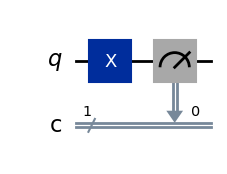

In [4]:
qc_a = QuantumCircuit(1, 1)   # 1 qubit (starts in |0>), 1 classical bit
qc_a.x(0)
qc_a.measure(0, 0)
qc_a.draw("mpl")

Circuit A counts: {'1': 100}


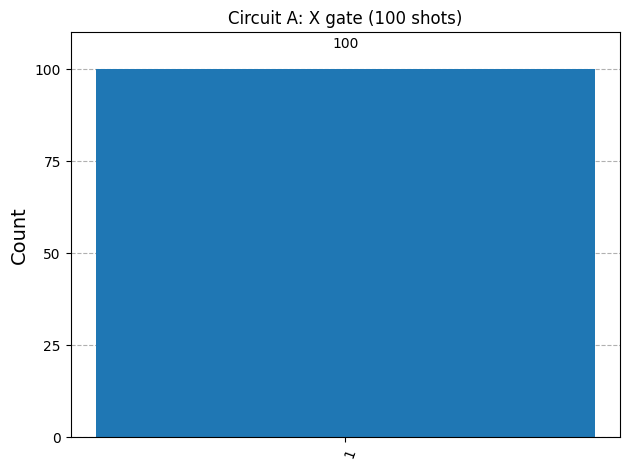

In [5]:
counts_a = sim.run(transpile(qc_a, sim), shots=SHOTS).result().get_counts()
print("Circuit A counts:", counts_a)
plot_histogram(counts_a, title="Circuit A: X gate (100 shots)")

## 4. Circuit B — two X gates, then measure

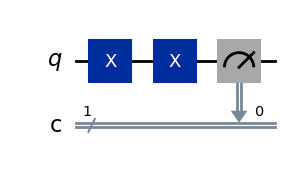

In [6]:
qc_b = QuantumCircuit(1, 1)
qc_b.x(0)
qc_b.x(0)
qc_b.measure(0, 0)
qc_b.draw("mpl")

Circuit B counts: {'0': 100}


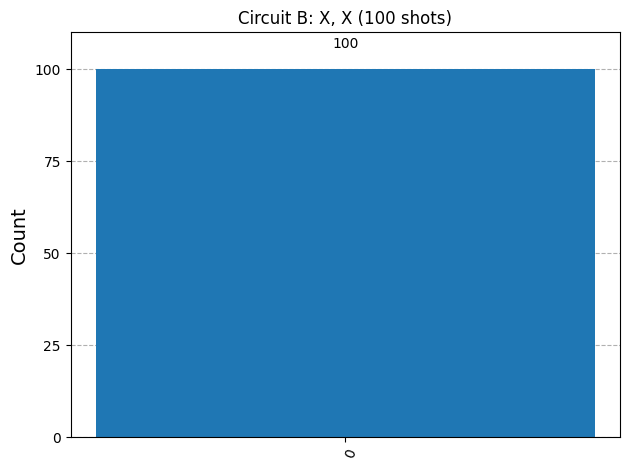

In [7]:
counts_b = sim.run(transpile(qc_b, sim), shots=SHOTS).result().get_counts()
print("Circuit B counts:", counts_b)
plot_histogram(counts_b, title="Circuit B: X, X (100 shots)")

## 5. Circuit C — H gate, then measure

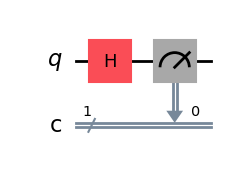

In [8]:
qc_c = QuantumCircuit(1, 1)
qc_c.h(0)
qc_c.measure(0, 0)
qc_c.draw("mpl")

Circuit C counts: {'0': 52, '1': 48}


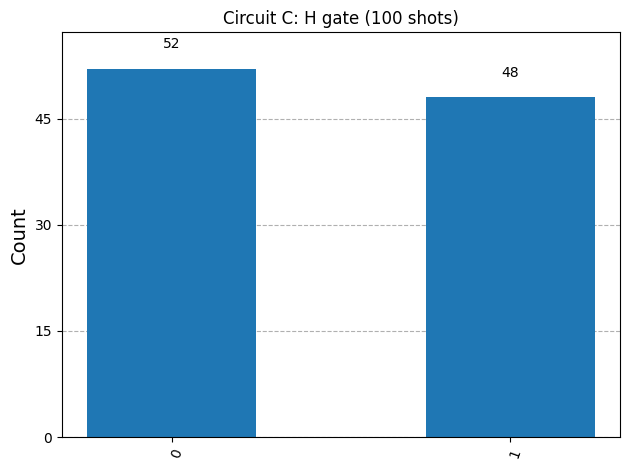

In [9]:
counts_c = sim.run(transpile(qc_c, sim), shots=SHOTS).result().get_counts()
print("Circuit C counts:", counts_c)
plot_histogram(counts_c, title="Circuit C: H gate (100 shots)")

## 6. Prediction vs. actual
The table below is built from the real counts. For A and B the prediction must match exactly. For C we accept anything within a reasonable statistical range of 50/50 (35–65 for each outcome).

In [10]:
results = {"A": counts_a, "B": counts_b, "C": counts_c}

def matches(name, counts):
    z, o = counts.get("0", 0), counts.get("1", 0)
    if name == "C":
        return 35 <= z <= 65 and 35 <= o <= 65
    return (z, o) == (predictions[name]["0"], predictions[name]["1"])

print(f"{'Circuit':<9}{'Predicted 0/1':<16}{'Actual 0/1':<13}Prediction held?")
print("-" * 52)
for name, counts in results.items():
    p = predictions[name]
    pred = f"{p['0']} / {p['1']}"
    act  = f"{counts.get('0', 0)} / {counts.get('1', 0)}"
    print(f"{name:<9}{pred:<16}{act:<13}{'Yes' if matches(name, counts) else 'No'}")

Circuit  Predicted 0/1   Actual 0/1   Prediction held?
----------------------------------------------------
A        0 / 100         0 / 100      Yes
B        100 / 0         100 / 0      Yes
C        50 / 50         52 / 48      Yes


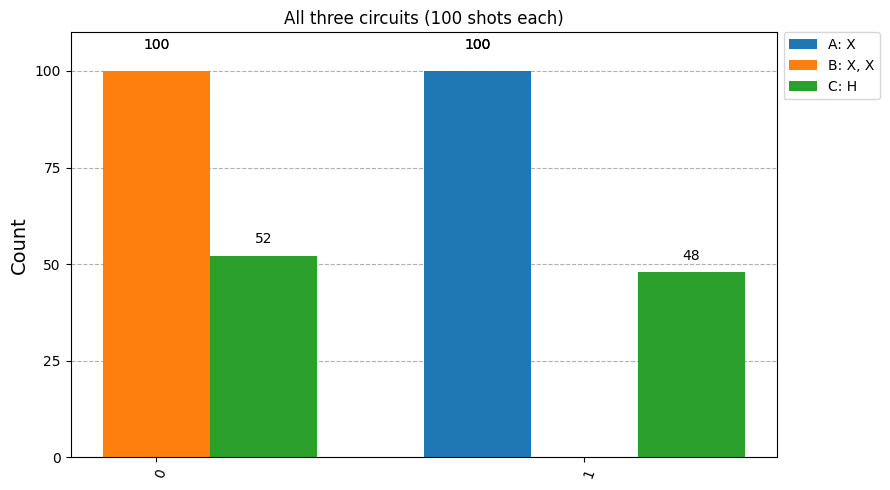

In [11]:
plot_histogram(list(results.values()),
               legend=["A: X", "B: X, X", "C: H"],
               title="All three circuits (100 shots each)",
               figsize=(9, 5))

## 7. Is Circuit C really random?
Running Circuit C several more times shows that the counts change every time, which answers the "will it always give the same result?" question.

In [12]:
compiled_c = transpile(qc_c, sim)
for i in range(1, 6):
    cnt = sim.run(compiled_c, shots=SHOTS).result().get_counts()
    print(f"Run {i}: 0 -> {cnt.get('0', 0):>3},  1 -> {cnt.get('1', 0):>3}")

Run 1: 0 ->  51,  1 ->  49
Run 2: 0 ->  49,  1 ->  51
Run 3: 0 ->  50,  1 ->  50
Run 4: 0 ->  50,  1 ->  50
Run 5: 0 ->  57,  1 ->  43


## 8. Conclusion

- **Circuit A (X):** The X gate flips |0⟩ to |1⟩, so every shot returned `1`. This matched the prediction.
- **Circuit B (X, X):** Two X gates cancel each other, so the qubit ends up back in |0⟩ and every shot returned `0`. This matched the prediction.
- **Circuit C (H):** H puts the qubit into an equal superposition of |0⟩ and |1⟩. The counts came out close to 50/50 but not exactly, and they were different on each repeat run. Circuit C does **not** always give the same result.

**Main idea:** X and X–X are deterministic (the outcome is certain), while H is probabilistic (the outcome is random until measured).

**Checklist:** 3 circuits ✔  predictions before running ✔  100 shots each ✔  counts recorded ✔  histograms ✔  comparison ✔

## 9. (Optional) Run the same circuits on a real IBM Quantum device

You need an IBM Cloud API key from https://quantum.cloud.ibm.com. Real devices have noise, so A and B may show a few wrong shots (for example 98 × `1` and 2 × `0`).

**Step 1 (once):** paste your key into the cell below and run it. **Step 2:** delete the key from the cell afterwards so it never ends up in a file you share or upload. If no credentials are saved, the next cell simply skips the hardware run.

In [13]:
# %pip install -q qiskit-ibm-runtime
from qiskit_ibm_runtime import QiskitRuntimeService

IBM_API_KEY  = "PASTE_YOUR_API_KEY_HERE"   # delete after saving
IBM_INSTANCE = ""                          # optional: instance name or CRN

if IBM_API_KEY != "PASTE_YOUR_API_KEY_HERE":
    opts = dict(channel="ibm_quantum_platform", token=IBM_API_KEY,
                overwrite=True, set_as_default=True)
    if IBM_INSTANCE:
        opts["instance"] = IBM_INSTANCE
    QiskitRuntimeService.save_account(**opts)
    print("Credentials saved. Delete your key from this cell now.")
else:
    print("No new key entered; using saved credentials if available.")

No new key entered; using saved credentials if available.


In [14]:
from qiskit_ibm_runtime import SamplerV2
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

try:
    service = QiskitRuntimeService()
    hw = service.least_busy(operational=True, simulator=False, min_num_qubits=1)
except Exception as err:
    hw = None
    print("Skipping the hardware run (no usable IBM credentials):", err)

if hw is not None:
    print("Running on:", hw.name)
    pm = generate_preset_pass_manager(backend=hw, optimization_level=0)   # keep X, X as written
    job = SamplerV2(mode=hw).run([pm.run(q) for q in (qc_a, qc_b, qc_c)], shots=SHOTS)
    print("Job ID:", job.job_id(), "- waiting for the result ...")
    pubs = job.result()
    hw_counts = [p.data.c.get_counts() for p in pubs]   # register is named 'c' by default
    for label, cnt in zip(["A", "B", "C"], hw_counts):
        print(f"Circuit {label}: {cnt}")
    display(plot_histogram(hw_counts, legend=["A: X", "B: X, X", "C: H"],
                           title=f"IBM hardware ({hw.name}), 100 shots", figsize=(9, 5)))

Skipping the hardware run (no usable IBM credentials): "Unable to find account. Please make sure an account with the channel name 'ibm_quantum_platform' is saved."
